### Libraries loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, GaussianNB,BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor,plot_tree #Decision Tree 
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.svm import SVC # For classification
from sklearn.svm import SVR # For Regression
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor # KNN For Classification, Regression



## dataset loading

In [2]:
# Load dataset
file = "dataset/rwanda_o_level_final_dataset_100000.csv"
df=pd.read_csv(file)
df.head()

,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,Female,68.8,84.2,59.3,74.0,80.7,62.2,74.6,NaN,68.4,69.91,Pass
1,S3-000002,Female,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,Pass
2,S3-000003,Female,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,Pass
3,S3-000004,Female,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,Pass
4,S3-000005,Female,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,Pass


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 100000
Number of columns: 13


In [4]:
len(df)

100000

In [5]:
df.columns

Index(['Student_ID', 'Gender', 'Biology_and_Health_Sciences', 'Chemistry',
       'English', 'Entrepreneurship', 'Geography_and_Environment',
       'History_and_Citizenship', 'Kinyarwanda', 'Mathematics', 'Physics',
       'Total_Marks', 'Status'],
      dtype='str')

In [6]:
# missing values
df.isnull().sum()

Student_ID                        0
Gender                         2000
Biology_and_Health_Sciences    3000
Chemistry                      3500
English                        2500
Entrepreneurship               3000
Geography_and_Environment      2500
History_and_Citizenship        3000
Kinyarwanda                    2500
Mathematics                    3500
Physics                        3000
Total_Marks                       0
Status                            0
dtype: int64

In [7]:
numerical_columns = [
    "Biology_and_Health_Sciences",
    "Chemistry",
    "English",
    "Entrepreneurship",
    "Geography_and_Environment",
    "History_and_Citizenship",
    "Kinyarwanda",
    "Mathematics",
    "Physics"
]

categorical_columns = [
    "Gender"
]

## Outlier Detection

In [8]:
# Detect and display outliers using IQR
for column in numerical_columns:

    # Calculate Q1 and Q3
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Define lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Find outliers
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{'='*60}")
    print(f"Column: {column}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")

    if len(outliers) > 0:
        print("\nOutliers:")
        display(outliers[[column]])
    else:
        print("No outliers detected.")


Column: Biology_and_Health_Sciences
Q1: 50.70
Q3: 71.30
IQR: 20.60
Lower Bound: 19.80
Upper Bound: 102.20
Number of Outliers: 233

Outliers:


,Biology_and_Health_Sciences
430,19.8
856,16.9
1812,18.8
2437,16.7
3440,19.6
...,...
97060,13.5
97752,19.6
98255,16.9
98372,17.2



Column: Chemistry
Q1: 48.10
Q3: 69.80
IQR: 21.70
Lower Bound: 15.55
Upper Bound: 102.35
Number of Outliers: 271

Outliers:


,Chemistry
178,12.1
392,7.1
1879,14.1
2437,5.8
3119,12.9
...,...
98131,14.7
98150,14.8
98352,14.8
98901,13.2



Column: English
Q1: 52.80
Q3: 71.20
IQR: 18.40
Lower Bound: 25.20
Upper Bound: 98.80
Number of Outliers: 539

Outliers:


,English
284,100.0
313,23.9
507,16.6
551,21.1
803,100.0
...,...
99135,100.0
99411,15.0
99474,99.6
99781,100.0



Column: Entrepreneurship
Q1: 56.40
Q3: 73.60
IQR: 17.20
Lower Bound: 30.60
Upper Bound: 99.40
Number of Outliers: 587

Outliers:


,Entrepreneurship
392,24.5
401,100.0
571,100.0
660,29.2
690,100.0
...,...
98688,100.0
99512,25.4
99535,99.8
99810,100.0



Column: Geography_and_Environment
Q1: 53.80
Q3: 72.10
IQR: 18.30
Lower Bound: 26.35
Upper Bound: 99.55
Number of Outliers: 575

Outliers:


,Geography_and_Environment
571,100.0
646,26.2
856,16.3
968,100.0
1180,100.0
...,...
99353,100.0
99376,99.6
99535,100.0
99606,24.6



Column: History_and_Citizenship
Q1: 52.80
Q3: 71.10
IQR: 18.30
Lower Bound: 25.35
Upper Bound: 98.55
Number of Outliers: 564

Outliers:


,History_and_Citizenship
66,100.0
149,24.8
198,100.0
392,20.9
605,25.2
...,...
99782,18.3
99813,100.0
99830,100.0
99866,15.0



Column: Kinyarwanda
Q1: 57.40
Q3: 74.60
IQR: 17.20
Lower Bound: 31.60
Upper Bound: 100.40
Number of Outliers: 332

Outliers:


,Kinyarwanda
149,31.6
421,29.8
450,20.5
469,31.4
738,30.0
...,...
96671,22.6
97060,27.4
97753,25.7
98204,30.9



Column: Mathematics
Q1: 46.60
Q3: 69.90
IQR: 23.30
Lower Bound: 11.65
Upper Bound: 104.85
Number of Outliers: 1042

Outliers:


,Mathematics
95,147.1
310,190.9
363,197.8
510,11.4
548,183.5
...,...
99428,164.9
99714,203.3
99881,150.9
99894,5.4



Column: Physics
Q1: 48.10
Q3: 69.90
IQR: 21.80
Lower Bound: 15.40
Upper Bound: 102.60
Number of Outliers: 259

Outliers:


,Physics
1105,14.9
1290,13.7
1784,15.1
1888,14.5
2008,11.8
...,...
96131,11.3
96530,12.2
98445,14.6
98901,13.7


## Use BOX PLOT to detect outliers

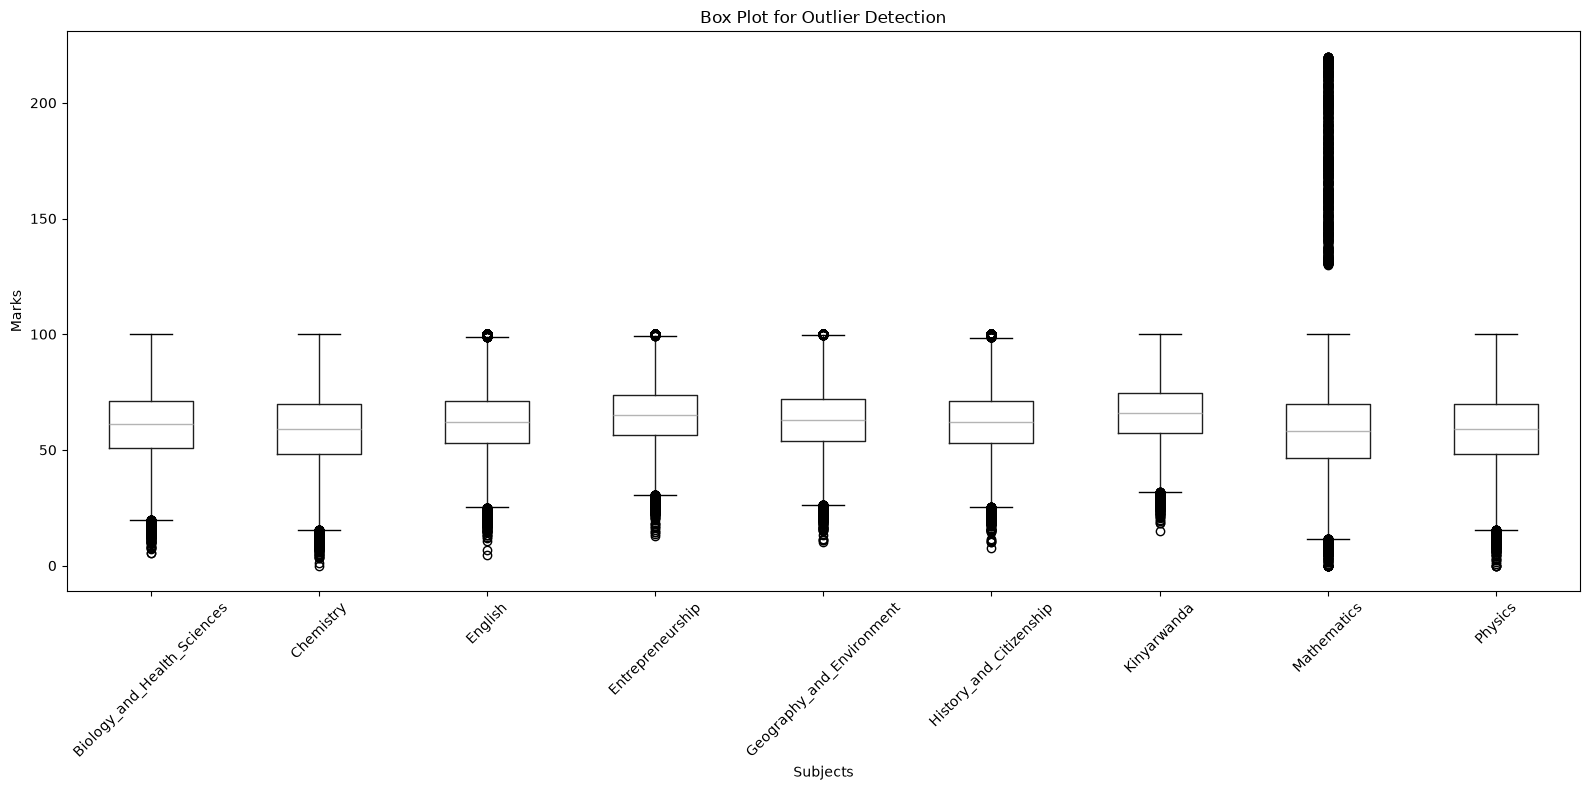

In [9]:
# Create box plots for all numerical columns
plt.figure(figsize=(16, 8))

df[numerical_columns].boxplot()

plt.title("Box Plot for Outlier Detection")
plt.ylabel("Marks")
plt.xlabel("Subjects")
plt.xticks(rotation=45)
plt.grid(False)

plt.tight_layout()
plt.show()

## REMOVE MISSING VALUES FOR ALL NUMERICAL CL=OLUMN BCZ THEY CONTAIN OUTLIERS USE MEDIAN

In [10]:
# Fill missing values in numerical columns using median
for column in numerical_columns:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

# Check missing values after filling
print("Missing values after preprocessing:")
print(df[numerical_columns].isnull().sum())

Missing values after preprocessing:
Biology_and_Health_Sciences    0
Chemistry                      0
English                        0
Entrepreneurship               0
Geography_and_Environment      0
History_and_Citizenship        0
Kinyarwanda                    0
Mathematics                    0
Physics                        0
dtype: int64


In [11]:
df.head()

,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,Female,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4,69.91,Pass
1,S3-000002,Female,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,Pass
2,S3-000003,Female,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,Pass
3,S3-000004,Female,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,Pass
4,S3-000005,Female,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,Pass


In [12]:
df.isna().sum()

Student_ID                        0
Gender                         2000
Biology_and_Health_Sciences       0
Chemistry                         0
English                           0
Entrepreneurship                  0
Geography_and_Environment         0
History_and_Citizenship           0
Kinyarwanda                       0
Mathematics                       0
Physics                           0
Total_Marks                       0
Status                            0
dtype: int64

In [13]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [14]:
df.Gender.isna().sum()
df['Gender'].isna().sum()

np.int64(0)

## OUTLIER REMOVAL

In [15]:
# Store the original number of rows
original_rows = len(df)

# Drop outliers using IQR
for column in numerical_columns:

    # Calculate Q1 and Q3
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Define lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Detect outliers
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers removed")

    # Drop detected outliers
    df = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

# Reset index
df.reset_index(drop=True, inplace=True)

# Display results
print("\n========================================")
print("OUTLIER REMOVAL SUMMARY")
print("========================================")
print(f"Rows before removing outliers: {original_rows}")
print(f"Rows after removing outliers:  {len(df)}")
print(f"Total rows removed:            {original_rows - len(df)}")

Biology_and_Health_Sciences: 315 outliers removed
Chemistry: 336 outliers removed
English: 675 outliers removed
Entrepreneurship: 747 outliers removed
Geography_and_Environment: 646 outliers removed
History_and_Citizenship: 673 outliers removed
Kinyarwanda: 675 outliers removed
Mathematics: 1004 outliers removed
Physics: 520 outliers removed

OUTLIER REMOVAL SUMMARY
Rows before removing outliers: 100000
Rows after removing outliers:  94409
Total rows removed:            5591


## check duplicate

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.columns

Index(['Student_ID', 'Gender', 'Biology_and_Health_Sciences', 'Chemistry',
       'English', 'Entrepreneurship', 'Geography_and_Environment',
       'History_and_Citizenship', 'Kinyarwanda', 'Mathematics', 'Physics',
       'Total_Marks', 'Status'],
      dtype='str')

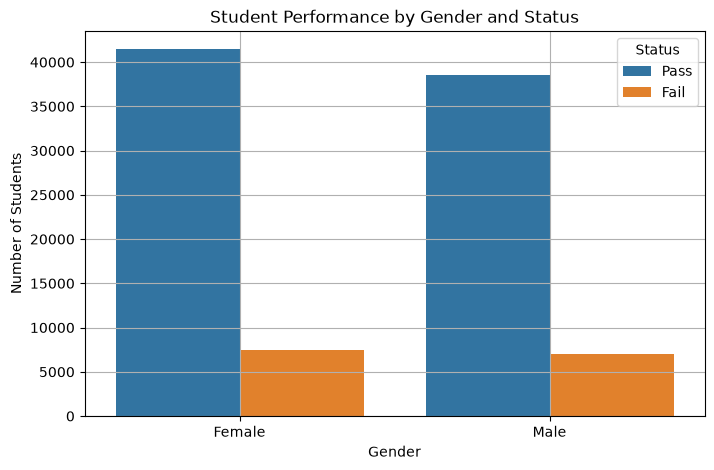

In [18]:

# Visualize students by Gender and Status
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Gender',
    hue='Status'
)

plt.title('Student Performance by Gender and Status')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.grid()
plt.legend(title='Status')

plt.show()

   Gender Status  Number_of_Students
0  Female   Fail               14512
1  Female   Pass               34421
2    Male   Fail               13436
3    Male   Pass               32040


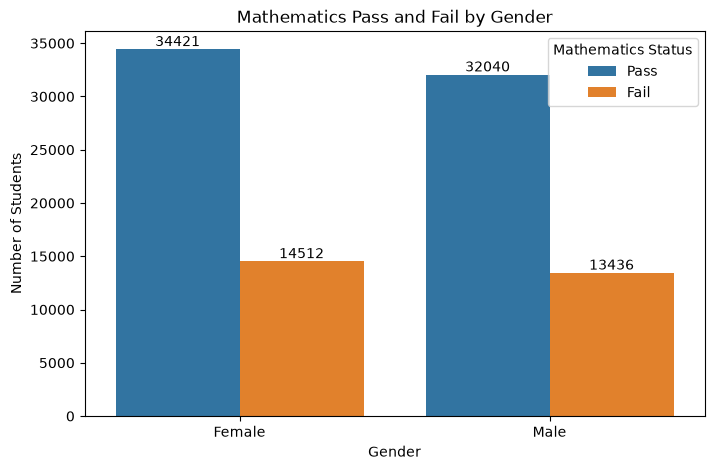

In [19]:

# Create Mathematics status
df['Status'] = df['Mathematics'].apply(
    lambda x: 'Pass' if x >= 50 else 'Fail'
)
# Count students by Gender and Mathematics Status
math_gender = df.groupby(
    ['Gender', 'Status']
).size().reset_index(name='Number_of_Students')
# Display counts
print(math_gender)
# Visualize
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='Gender',
    hue='Status'
)
# Display numbers on bars
for container in ax.containers:
    ax.bar_label(container)
plt.title('Mathematics Pass and Fail by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.legend(title='Mathematics Status')

plt.show()

## Encode our Gender

In [20]:
gender_encoder = LabelEncoder()
# Transform Gender
df['Gender'] = gender_encoder.fit_transform(df['Gender'])

# Display encoding mapping
for label, encoded_value in zip(
    gender_encoder.classes_,
    gender_encoder.transform(gender_encoder.classes_)
):
    print(f"{label} = {encoded_value}")

Female = 0
Male = 1


In [21]:
status_encoder = LabelEncoder()
# Transform Gender
df['Status'] = status_encoder.fit_transform(df['Status'])

# Display encoding mapping
for label, encoded_value in zip(
    status_encoder.classes_,
    status_encoder.transform(status_encoder.classes_)
):
    print(f"{label} = {encoded_value}")

Fail = 0
Pass = 1


In [22]:
df.head()

,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4,69.91,1
1,S3-000002,0,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,1
2,S3-000003,0,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,1
3,S3-000004,0,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,1
4,S3-000005,0,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,1


In [23]:
# Count total females (Female = 0)
total_female = (df['Gender'] == 0).sum()

print("Total Female:", total_female)

Total Female: 48933


In [24]:
# Count total females (Female = 0)
total_male = (df['Gender'] == 1).sum()

print("Total male:", total_male)

Total male: 45476


In [25]:
df.head()

,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4,69.91,1
1,S3-000002,0,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,1
2,S3-000003,0,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,1
3,S3-000004,0,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,1
4,S3-000005,0,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,1


In [26]:
df =df.drop(['Student_ID'], axis=1)
df.head()

,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4,69.91,1
1,0,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,1
2,0,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,1
3,0,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,1
4,0,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,1


In [27]:
correlation = df.corr(
    numeric_only=True
)

print(
    correlation["Status"]
    .sort_values(ascending=False)
)

Status                         1.000000
Mathematics                    0.761219
Total_Marks                    0.660329
Physics                        0.539433
Chemistry                      0.536488
Biology_and_Health_Sciences    0.525227
English                        0.498968
Geography_and_Environment      0.497885
History_and_Citizenship        0.496849
Kinyarwanda                    0.481304
Entrepreneurship               0.476551
Gender                         0.001222
Name: Status, dtype: float64


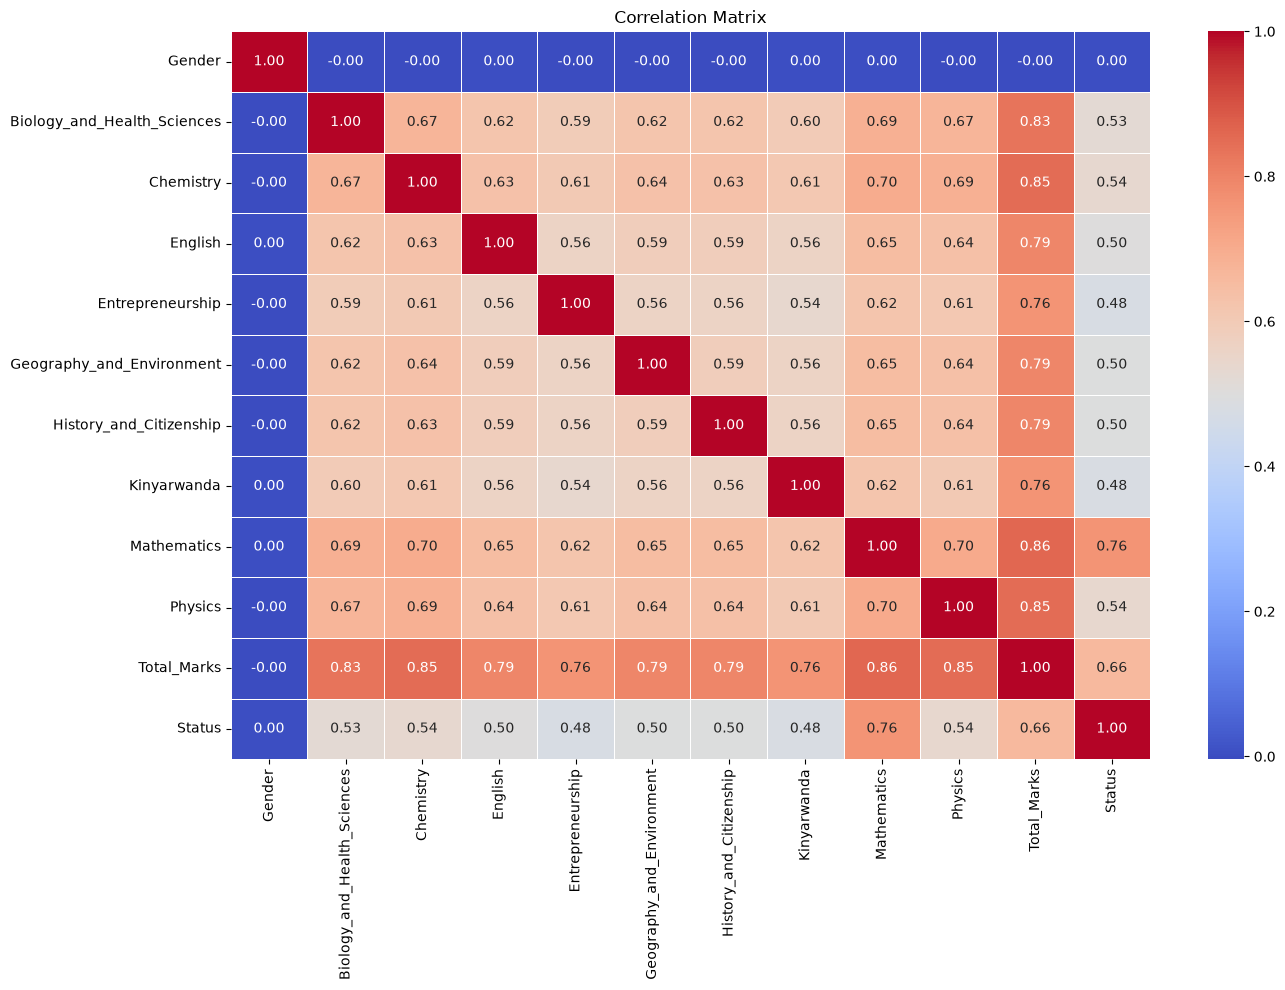

In [28]:
# Calculate correlation matrix
correlation = df.corr(numeric_only=True)

# Draw correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,          # Show correlation values
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [29]:
df = df.drop(['Gender'], axis=1)

In [30]:
X = df.drop(['Total_Marks','Status'], axis=1)
y= df['Status']

In [31]:
X

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4
1,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4
2,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5
3,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8
4,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2
...,...,...,...,...,...,...,...,...,...
94404,71.3,77.1,83.3,70.9,82.5,69.3,69.4,79.1,80.5
94405,66.2,67.8,48.1,61.7,70.0,60.5,61.8,45.4,75.5
94406,35.6,46.3,58.1,48.2,52.8,42.7,54.3,37.9,39.7
94407,56.6,57.2,47.7,60.4,79.8,52.5,66.1,56.1,65.0


In [32]:
# Keep raw marks until after the train/test split.
X.head()

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4
1,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4
2,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5
3,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8
4,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2


In [33]:
# Concatenate X and y
df = pd.concat([X, y], axis=1)

# Display result
df.head()

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Status
0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4,1
1,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,1
2,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,1
3,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,1
4,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,1


## Save a Cleaned Dataset

In [34]:
df.to_csv('dataset/rwanda_o_level_final_dataset_cleaned_100000.csv')
print("Data Save")

Data Save


In [35]:
X

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,68.8,84.2,59.3,74.0,80.7,62.2,74.6,58.1,68.4
1,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4
2,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5
3,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8
4,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2
...,...,...,...,...,...,...,...,...,...
94404,71.3,77.1,83.3,70.9,82.5,69.3,69.4,79.1,80.5
94405,66.2,67.8,48.1,61.7,70.0,60.5,61.8,45.4,75.5
94406,35.6,46.3,58.1,48.2,52.8,42.7,54.3,37.9,39.7
94407,56.6,57.2,47.7,60.4,79.8,52.5,66.1,56.1,65.0


In [36]:
X.columns

Index(['Biology_and_Health_Sciences', 'Chemistry', 'English',
       'Entrepreneurship', 'Geography_and_Environment',
       'History_and_Citizenship', 'Kinyarwanda', 'Mathematics', 'Physics'],
      dtype='str')

In [37]:
y

0        1
1        1
2        1
3        1
4        1
        ..
94404    1
94405    0
94406    0
94407    1
94408    0
Name: Status, Length: 94409, dtype: int64

## DATASET SPLITTING (X_train, X_test, y_train, y_test)

In [38]:
# Fit scaling values on training rows only; reuse them for test and deployment.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
feature_min = X_train_raw.min()
feature_range = (X_train_raw.max() - feature_min).replace(0, 1)
X_train = (X_train_raw - feature_min) / feature_range
X_test = (X_test_raw - feature_min) / feature_range
print("Train samples:", X_train.shape, "Test samples:", X_test.shape)

Train samples: (75527, 9) Test samples: (18882, 9)


## Model Selection

# 1. Logistic Regression

In [39]:
model = LogisticRegression()
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Model prediction



In [40]:
y_pred = model.predict(X_test)
y_pred


array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [41]:
y_test.values

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [42]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Actual_Class"] = results["Actual"].map({
    0: "Fail",
    1: "Pass"
})

results["Predicted_Class"] = results["Predicted"].map({
    0: "Fail",
    1: "Pass"
})

results

,Actual,Predicted,Actual_Class,Predicted_Class
0,1,1,Pass,Pass
1,1,1,Pass,Pass
2,1,1,Pass,Pass
3,1,1,Pass,Pass
4,1,1,Pass,Pass
...,...,...,...,...
18877,0,0,Fail,Fail
18878,1,1,Pass,Pass
18879,0,0,Fail,Fail
18880,1,1,Pass,Pass


In [43]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[ 5513,    77],
       [   26, 13266]])

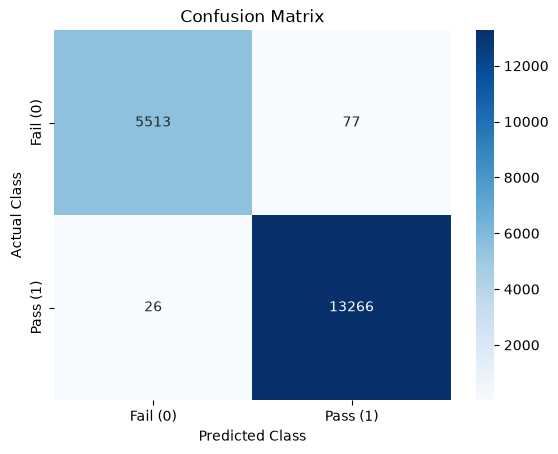

In [44]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

In [45]:
print(accuracy_score(y_test, y_pred))

0.9945450693782438


In [46]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      5590
           1       0.99      1.00      1.00     13292

    accuracy                           0.99     18882
   macro avg       0.99      0.99      0.99     18882
weighted avg       0.99      0.99      0.99     18882



## Test on new Sample (External from our model)

In [47]:
import pandas as pd

# New external samples
new_students = pd.DataFrame({
    "Biology_and_Health_Sciences": [5, 5, 2, 45, 68],
    "Chemistry":                   [7, 0, 78, 40, 65],
    "English":                     [5, 42, 80, 48, 72],
    "Entrepreneurship":            [8, 38, 85, 44, 75],
    "Geography_and_Environment":   [7, 35, 76, 46, 69],
    "History_and_Citizenship":     [8, 4, 79, 43, 71],
    "Kinyarwanda":                 [4, 5, 81, 47, 73],
    "Mathematics":                 [85, 5, 90, 38, 77],
    "Physics":                     [8, 8, 4, 35, 70]
})

# new_students

# Apply exactly the same transformation used for the training data.
new_students_scaled = (new_students[X.columns] - feature_min) / feature_range
new_students_scaled

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,-0.205584,-0.125908,-0.308345,-0.370992,-0.306475,-0.286337,-0.458333,0.822064,-0.141427
1,-0.205584,-0.210654,0.214993,0.087023,0.096403,-0.344477,-0.442901,-0.126928,-0.141427
2,-0.243655,0.733656,0.752475,0.804580,0.686331,0.745640,0.729938,0.881376,-0.191489
3,0.302030,0.273608,0.299859,0.178626,0.254676,0.222384,0.205247,0.264531,0.196496
4,0.593909,0.576271,0.639321,0.651908,0.585612,0.629360,0.606481,0.727165,0.634543


In [48]:
# Predict new external samples
new_predictions = model.predict(new_students_scaled)

new_predictions

array([1, 0, 1, 0, 1])

## NAIVE BAYES

In [49]:
model_naive = BernoulliNB()
model_naive.fit(X_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[22358.,53169.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-1.22,-0.35]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 9)","[[22357.,22355.,22355.,...,22354.,22353.,22354.], [53168.,53169.,53169.,...,53169.,53169.,53168.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 9)","[[-0.,-0.,-0.,...,-0.,-0.,-0.], [-0.,-0.,-0.,...,-0.,-0.,-0.]]"


In [50]:
y_pred_naive = model_naive.predict(X_test)
y_pred_naive


array([1, 1, 1, ..., 1, 1, 1], shape=(18882,))

In [51]:
y_test.values

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [52]:
cm = confusion_matrix(y_test,y_pred_naive)
cm

array([[   10,  5580],
       [    0, 13292]])

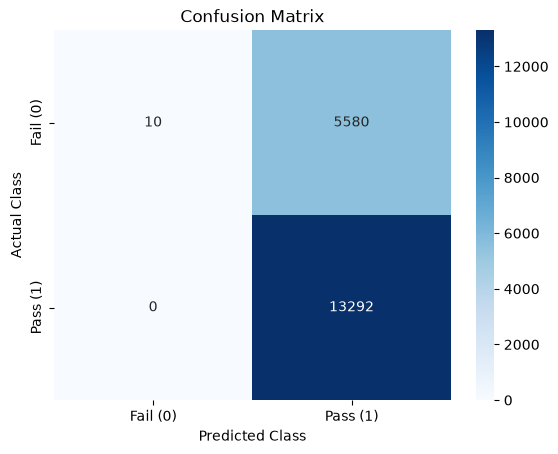

In [53]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_naive, labels=[0, 1])

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

In [54]:
print(accuracy_score(y_test, y_pred_naive))

0.7044804575786463


In [55]:
print(classification_report(y_test, y_pred_naive))

              precision    recall  f1-score   support

           0       1.00      0.00      0.00      5590
           1       0.70      1.00      0.83     13292

    accuracy                           0.70     18882
   macro avg       0.85      0.50      0.42     18882
weighted avg       0.79      0.70      0.58     18882



In [56]:
# New external samples
new_students = pd.DataFrame({
    "Biology_and_Health_Sciences": [5, 5, 2, 45, 68],
    "Chemistry":                   [7, 0, 78, 40, 65],
    "English":                     [5, 42, 80, 48, 72],
    "Entrepreneurship":            [8, 38, 85, 44, 75],
    "Geography_and_Environment":   [7, 35, 76, 46, 69],
    "History_and_Citizenship":     [8, 4, 79, 43, 71],
    "Kinyarwanda":                 [4, 5, 81, 47, 73],
    "Mathematics":                 [85, 5, 90, 38, 77],
    "Physics":                     [8, 8, 4, 35, 70]
})

# new_students


# Apply exactly the same transformation used for the training data.
new_students_scaled = (new_students[X.columns] - feature_min) / feature_range
new_students_scaled

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,-0.205584,-0.125908,-0.308345,-0.370992,-0.306475,-0.286337,-0.458333,0.822064,-0.141427
1,-0.205584,-0.210654,0.214993,0.087023,0.096403,-0.344477,-0.442901,-0.126928,-0.141427
2,-0.243655,0.733656,0.752475,0.804580,0.686331,0.745640,0.729938,0.881376,-0.191489
3,0.302030,0.273608,0.299859,0.178626,0.254676,0.222384,0.205247,0.264531,0.196496
4,0.593909,0.576271,0.639321,0.651908,0.585612,0.629360,0.606481,0.727165,0.634543


In [57]:
new_predictions = model_naive.predict(new_students_scaled)

new_predictions

array([0, 0, 0, 1, 1])

In [58]:
X_test

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
58262,0.606599,0.725182,0.577086,0.806107,0.530935,0.767442,0.552469,0.613286,0.430538
27353,0.662437,0.841404,0.602546,0.796947,0.628777,0.433140,0.685185,0.674970,0.774718
50213,0.525381,0.541162,0.586987,0.406107,0.464748,0.498547,0.641975,0.552788,0.458073
89269,0.515228,0.585956,0.680339,0.361832,0.578417,0.343023,0.399691,0.510083,0.496871
19620,0.572335,0.550847,0.490806,0.335878,0.646043,0.720930,0.554012,0.601423,0.703379
...,...,...,...,...,...,...,...,...,...
41129,0.550761,0.405569,0.514851,0.306870,0.497842,0.382267,0.362654,0.332147,0.371715
72677,0.483503,0.446731,0.321075,0.290076,0.402878,0.375000,0.523148,0.615658,0.279099
88978,0.222081,0.322034,0.261669,0.254962,0.398561,0.328488,0.300926,0.319098,0.249061
27198,0.535533,0.748184,0.523338,0.532824,0.483453,0.392442,0.603395,0.670225,0.627034


## Decision Tree Classifier

In [59]:
model_decision_tree = DecisionTreeClassifier()
model_decision_tree.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [60]:
ypred_model_decision_tree = model_decision_tree.predict(X_test)
ypred_model_decision_tree

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [61]:
y_test.values

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [62]:
print(accuracy_score(y_test,ypred_model_decision_tree))

1.0


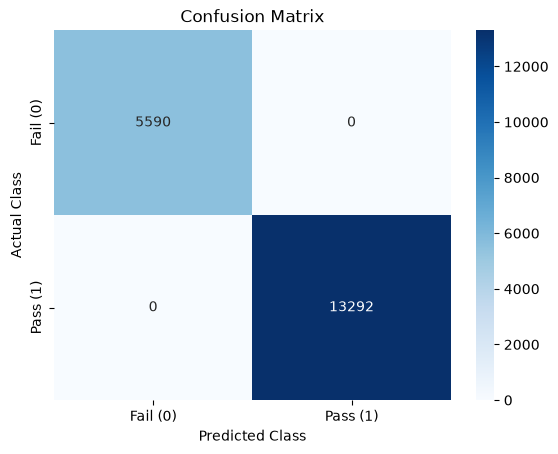

In [63]:
# Generate confusion matrix
cm = confusion_matrix(y_test, ypred_model_decision_tree, labels=[0, 1])

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

## Testing on new samples

In [64]:
# New external samples
new_students = pd.DataFrame({
    "Biology_and_Health_Sciences": [5, 5, 2, 45, 68],
    "Chemistry":                   [7, 0, 78, 40, 65],
    "English":                     [5, 42, 80, 48, 72],
    "Entrepreneurship":            [85, 38, 85, 44, 75],
    "Geography_and_Environment":   [7, 35, 76, 46, 69],
    "History_and_Citizenship":     [8, 4, 79, 43, 71],
    "Kinyarwanda":                 [4, 5, 81, 47, 73],
    "Mathematics":                 [8, 5, 90, 38, 77],
    "Physics":                     [8, 8, 4, 35, 70]
})

# new_students


# Apply exactly the same transformation used for the training data.
new_students_scaled = (new_students[X.columns] - feature_min) / feature_range
new_students_scaled

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics
0,-0.205584,-0.125908,-0.308345,0.804580,-0.306475,-0.286337,-0.458333,-0.091340,-0.141427
1,-0.205584,-0.210654,0.214993,0.087023,0.096403,-0.344477,-0.442901,-0.126928,-0.141427
2,-0.243655,0.733656,0.752475,0.804580,0.686331,0.745640,0.729938,0.881376,-0.191489
3,0.302030,0.273608,0.299859,0.178626,0.254676,0.222384,0.205247,0.264531,0.196496
4,0.593909,0.576271,0.639321,0.651908,0.585612,0.629360,0.606481,0.727165,0.634543


In [65]:
new_predictions = model_decision_tree.predict(new_students_scaled)
new_predictions

array([0, 0, 1, 0, 1])

## Random Forest

In [66]:
model_rf = RandomForestClassifier()
model_rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [67]:
y_pred_rf = model_rf.predict(X_test)
y_pred_rf

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [68]:
y_test.values

array([1, 1, 1, ..., 0, 1, 1], shape=(18882,))

In [69]:
print(accuracy_score(y_test,y_pred_rf))

1.0


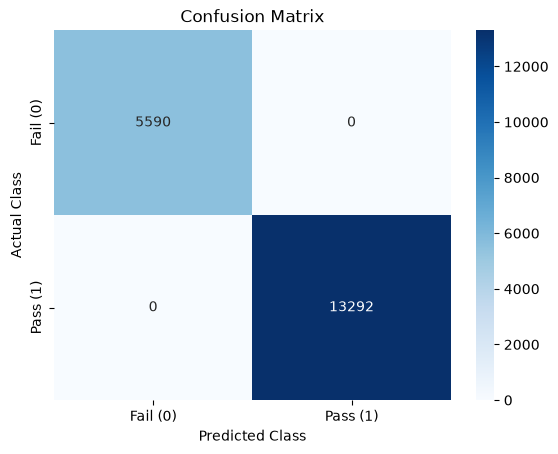

In [70]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

In [71]:
importances = model_rf.feature_importances_
feature_names = X.columns

feat_imp = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feat_imp = feat_imp.sort_values(by='Importance', ascending=False)
print(feat_imp)

                       Feature  Importance
7                  Mathematics    0.808657
8                      Physics    0.058584
1                    Chemistry    0.047994
0  Biology_and_Health_Sciences    0.044763
4    Geography_and_Environment    0.015246
2                      English    0.012840
5      History_and_Citizenship    0.007764
6                  Kinyarwanda    0.002731
3             Entrepreneurship    0.001419


## APPLY K-FOLD CROSS VALIDATION


Logistic Regression
Fold accuracies: [0.9942 0.9932 0.9939 0.9932 0.9943]
Mean accuracy: 0.9938
Standard deviation: 0.0005

Bernoulli Naive Bayes
Fold accuracies: [0.7043 0.7046 0.7044 0.7045 0.7041]
Mean accuracy: 0.7044
Standard deviation: 0.0002

Decision Tree
Fold accuracies: [1. 1. 1. 1. 1.]
Mean accuracy: 1.0000
Standard deviation: 0.0000

Random Forest
Fold accuracies: [1. 1. 1. 1. 1.]
Mean accuracy: 1.0000
Standard deviation: 0.0000

Cross-validation comparison:
        Logistic Regression  Bernoulli Naive Bayes  Decision Tree  \
Fold 1               0.9942                 0.7043            1.0   
Fold 2               0.9932                 0.7046            1.0   
Fold 3               0.9939                 0.7044            1.0   
Fold 4               0.9932                 0.7045            1.0   
Fold 5               0.9943                 0.7041            1.0   

        Random Forest  
Fold 1            1.0  
Fold 2            1.0  
Fold 3            1.0  
Fold 4       

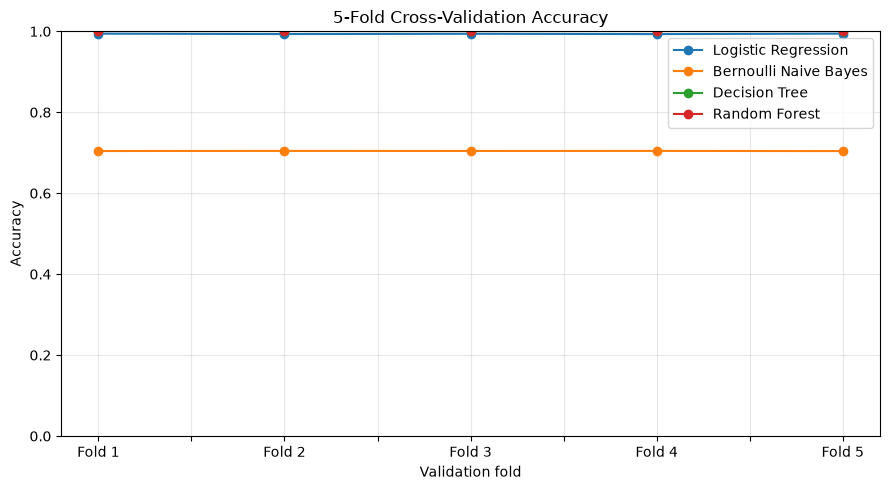

In [72]:
# 5-fold stratified cross-validation on the training set
# The held-out X_test/y_test remain reserved for final evaluation.
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models_for_cv = {
    "Logistic Regression": clone(model).set_params(max_iter=1000),
    "Bernoulli Naive Bayes": clone(model_naive),
    "Decision Tree": clone(model_decision_tree).set_params(random_state=42),
    "Random Forest": clone(model_rf).set_params(random_state=42, n_jobs=-1),
}
cv_results = {}
for name, estimator in models_for_cv.items():
    scores = cross_val_score(
        estimator, X_train, y_train,
        cv=cv, scoring="accuracy", n_jobs=1
    )
    cv_results[name] = scores
    print(f"\n{name}")
    print("Fold accuracies:", np.round(scores, 4))
    print(f"Mean accuracy: {scores.mean():.4f}")
    print(f"Standard deviation: {scores.std():.4f}")

# Compare validation accuracy across the five folds.
fold_scores = pd.DataFrame(cv_results, index=[f"Fold {i}" for i in range(1, 6)])
print("\nCross-validation comparison:")
print(fold_scores.round(4))

ax = fold_scores.plot(marker="o", figsize=(9, 5), ylim=(0, 1))
ax.set(title="5-Fold Cross-Validation Accuracy", xlabel="Validation fold", ylabel="Accuracy")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## SELECT THE BEST ACCURACY

In [73]:
# Original, untuned model comparison on training folds only.
mean_cv_scores = fold_scores.mean(axis=0)
display(mean_cv_scores.sort_values(ascending=False).rename("CV accuracy"))
print("Best untuned model:", mean_cv_scores.idxmax())
# Tuning below uses training rows only.

Random Forest            1.000000
Decision Tree            1.000000
Logistic Regression      0.993777
Bernoulli Naive Bayes    0.704384
Name: CV accuracy, dtype: float64

Best untuned model: Decision Tree


## detecting overfitting or underfitting or Best fit

In [74]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
# Majority-class accuracy gives a baseline for this dataset.
baseline = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X_train, y_train, cv=cv, scoring="accuracy"
)["test_score"].mean()

rows = []
for name, estimator in models_for_cv.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring="accuracy",
        return_train_score=True,
        n_jobs=1
    )

    train_acc = scores["train_score"].mean()
    val_acc = scores["test_score"].mean()
    gap = train_acc - val_acc

    # Diagnostic guidelines, not universal accuracy thresholds.
    if gap > 0.05:
        fit = "Possible overfitting"
    elif train_acc <= baseline + 0.02:
        fit = "Possible underfitting"
    else:
        fit = "Good fit on cross-validation"

    rows.append({
        "Model": name,
        "Train accuracy": train_acc,
        "CV accuracy": val_acc,
        "Train–CV gap": gap,
        "Interpretation": fit
    })
fit_results = pd.DataFrame(rows).set_index("Model")
print(f"Majority-class baseline accuracy: {baseline:.4f}\n")
display(fit_results.round(4))



Majority-class baseline accuracy: 0.7040



,Train accuracy,CV accuracy,Train–CV gap,Interpretation
Model,,,,
Logistic Regression,0.9937,0.9938,-0.0001,Good fit on cross-validation
Bernoulli Naive Bayes,0.7044,0.7044,0.0000,Possible underfitting
Decision Tree,1.0000,1.0000,0.0000,Good fit on cross-validation
Random Forest,1.0000,1.0000,0.0000,Good fit on cross-validation


## Original model bundle (after tuning below)

In [75]:
# Model export is performed after comparing the tuned algorithms (last section).
print("Run the tuning sections below, then export the winning tuned model.")

Run the tuning sections below, then export the winning tuned model.


## Load model for Future use

In [76]:
# Loading and predicting is demonstrated after the final tuned export.
print("Continue to hyperparameter tuning.")

Continue to hyperparameter tuning.


In [77]:
X_train.columns.tolist()

['Biology_and_Health_Sciences',
 'Chemistry',
 'English',
 'Entrepreneurship',
 'Geography_and_Environment',
 'History_and_Citizenship',
 'Kinyarwanda',
 'Mathematics',
 'Physics']

In [78]:
print('Final model predictions appear after tuning.')

Final model predictions appear after tuning.


## PREVIOUS NEW SAMPLES PREDICTION AND DISPLAY IN DF (BEST MODEL) Now the results are better using K-FOLD

In [79]:
# Predictions using the saved tuned model appear after the final export.
print("Continue to hyperparameter tuning.")

Continue to hyperparameter tuning.


# Hyper-Parameter Tuning

## 1. MANUAL HYPER-PARAMETER TUNNING

In [80]:
from sklearn.model_selection import ParameterGrid, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.base import clone

# All six methods compare the four algorithms with the same training sample/folds.
tune_size = min(3000, len(X_train))
if tune_size < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=tune_size,
        stratify=y_train, random_state=42)
else:
    X_tune, y_tune = X_train, y_train
tune_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

estimators = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=30, random_state=42, n_jobs=-1),
}
spaces = {
    "Logistic Regression": {"C": [0.1, 1.0, 10.0]},
    "Bernoulli Naive Bayes": {"alpha": [0.1, 1.0, 10.0],
                              "binarize": [0.3, 0.5]},
    "Decision Tree": {"max_depth": [2, 4, 8],
                      "min_samples_leaf": [1, 3]},
    "Random Forest": {"max_depth": [2, 4, 8],
                      "min_samples_leaf": [1, 3]},
}
tuning_rows = []
def score_candidate(name, params):
    estimator = clone(estimators[name]).set_params(**params)
    return cross_val_score(estimator, X_tune, y_tune, cv=tune_cv,
                           scoring="accuracy", n_jobs=1).mean()

def record(method, results):
    for name, (score, params) in results.items():
        tuning_rows.append({"Method": method, "Algorithm": name,
                            "CV accuracy": score, "Parameters": params})
    table = pd.DataFrame(tuning_rows)
    current = table[table["Method"] == method].sort_values(
        "CV accuracy", ascending=False, kind="stable")
    display(current)
    print(f"Best for {method}: {current.iloc[0]['Algorithm']} "
          f"(CV accuracy {current.iloc[0]['CV accuracy']:.4f})")

manual = {}
for name in estimators:
    candidates = list(ParameterGrid(spaces[name]))[:3]
    manual[name] = max(
        ((score_candidate(name, p), p) for p in candidates),
        key=lambda result: result[0])
record("Manual", manual)

,Method,Algorithm,CV accuracy,Parameters
2,Manual,Decision Tree,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
3,Manual,Random Forest,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
0,Manual,Logistic Regression,0.988000,{'C': 10.0}
1,Manual,Bernoulli Naive Bayes,0.862667,"{'alpha': 0.1, 'binarize': 0.3}"


Best for Manual: Decision Tree (CV accuracy 1.0000)


## 2. GRID-SEARCH HYPER-PARAMETER TUNNING

In [81]:
grid_results = {}
for name in estimators:
    search = GridSearchCV(estimators[name], spaces[name],
                          cv=tune_cv, scoring="accuracy", n_jobs=1)
    search.fit(X_tune, y_tune)
    grid_results[name] = (search.best_score_, search.best_params_)
record("Grid", grid_results)

,Method,Algorithm,CV accuracy,Parameters
6,Grid,Decision Tree,1.000,"{'max_depth': 2, 'min_samples_leaf': 1}"
7,Grid,Random Forest,1.000,"{'max_depth': 2, 'min_samples_leaf': 1}"
4,Grid,Logistic Regression,0.988,{'C': 10.0}
5,Grid,Bernoulli Naive Bayes,0.869,"{'alpha': 10.0, 'binarize': 0.3}"


Best for Grid: Decision Tree (CV accuracy 1.0000)


## 3. RANDOM SEARCH HYPER-PARAMETER TUNNING

In [82]:
random_results = {}
for name in estimators:
    search = RandomizedSearchCV(estimators[name], spaces[name],
        n_iter=min(4, len(ParameterGrid(spaces[name]))), cv=tune_cv,
        scoring="accuracy", random_state=42, n_jobs=1)
    search.fit(X_tune, y_tune)
    random_results[name] = (search.best_score_, search.best_params_)
record("Random", random_results)

,Method,Algorithm,CV accuracy,Parameters
10,Random,Decision Tree,1.000000,"{'min_samples_leaf': 1, 'max_depth': 2}"
11,Random,Random Forest,1.000000,"{'min_samples_leaf': 1, 'max_depth': 2}"
8,Random,Logistic Regression,0.988000,{'C': 10.0}
9,Random,Bernoulli Naive Bayes,0.862667,"{'binarize': 0.3, 'alpha': 0.1}"


Best for Random: Decision Tree (CV accuracy 1.0000)


## 4. BAYESISIAN Optimization HYPER-PARAMETER TUNNING

In [83]:
# Gaussian-process Bayesian search over each algorithm's finite parameter grid.
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from scipy.stats import norm
bayesian_results = {}
for name in estimators:
    candidates = list(ParameterGrid(spaces[name]))
    observed = {i: score_candidate(name, candidates[i])
                for i in range(min(2, len(candidates)))}
    for _ in range(min(3, len(candidates) - len(observed))):
        gp = GaussianProcessRegressor(kernel=Matern(length_scale=2.0, nu=2.5),
                                      alpha=1e-4, normalize_y=True,
                                      optimizer=None, random_state=42)
        gp.fit(np.array(list(observed)).reshape(-1, 1), list(observed.values()))
        remaining = np.array([i for i in range(len(candidates)) if i not in observed])
        mean, std = gp.predict(remaining.reshape(-1, 1), return_std=True)
        gain = mean - max(observed.values())
        z = gain / np.maximum(std, 1e-9)
        expected_improvement = gain * norm.cdf(z) + std * norm.pdf(z)
        choice = int(remaining[np.argmax(expected_improvement)])
        observed[choice] = score_candidate(name, candidates[choice])
    best = max(observed, key=observed.get)
    bayesian_results[name] = (observed[best], candidates[best])
record("Bayesian", bayesian_results)

,Method,Algorithm,CV accuracy,Parameters
14,Bayesian,Decision Tree,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
15,Bayesian,Random Forest,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
12,Bayesian,Logistic Regression,0.988000,{'C': 10.0}
13,Bayesian,Bernoulli Naive Bayes,0.862667,"{'alpha': 0.1, 'binarize': 0.3}"


Best for Bayesian: Decision Tree (CV accuracy 1.0000)


## 5. Gradient-based optimization (Logistic Regression only)

In [84]:
# The other models use discrete/tree parameters; their hyperparameter
# validation accuracy has no useful gradient. They are tuned in the other methods.
from scipy.optimize import minimize
def log_loss_objective(log_c):
    estimator = LogisticRegression(C=float(np.exp(log_c[0])),
                                   max_iter=1000, random_state=42)
    return -cross_val_score(estimator, X_tune, y_tune, cv=tune_cv,
                            scoring="neg_log_loss", n_jobs=1).mean()

result = minimize(log_loss_objective, [0.0], method="L-BFGS-B",
                  bounds=[(-4, 4)], options={"maxiter": 8, "eps": 0.05})
params = {"C": float(np.exp(result.x[0]))}
gradient_results = {
    "Logistic Regression": (score_candidate("Logistic Regression", params), params)
}
record("Gradient", gradient_results)

,Method,Algorithm,CV accuracy,Parameters
16,Gradient,Logistic Regression,0.994,{'C': 54.598150033144236}


Best for Gradient: Logistic Regression (CV accuracy 0.9940)


## 6. Population-based evolutionary optimization

In [85]:
from scipy.optimize import differential_evolution
evolutionary_results = {}
for name in estimators:
    candidates = list(ParameterGrid(spaces[name]))
    cache = {}
    def loss(point):
        index = int(np.clip(round(point[0]), 0, len(candidates) - 1))
        if index not in cache:
            cache[index] = score_candidate(name, candidates[index])
        return -cache[index]
    differential_evolution(loss, [(0, len(candidates) - 1)],
        popsize=4, maxiter=2, seed=42, polish=False)
    best = max(cache, key=cache.get)
    evolutionary_results[name] = (cache[best], candidates[best])
record("Evolutionary", evolutionary_results)

,Method,Algorithm,CV accuracy,Parameters
19,Evolutionary,Decision Tree,1.000,"{'max_depth': 4, 'min_samples_leaf': 1}"
20,Evolutionary,Random Forest,1.000,"{'max_depth': 4, 'min_samples_leaf': 1}"
17,Evolutionary,Logistic Regression,0.988,{'C': 10.0}
18,Evolutionary,Bernoulli Naive Bayes,0.869,"{'alpha': 10.0, 'binarize': 0.3}"


Best for Evolutionary: Decision Tree (CV accuracy 1.0000)


## Select, evaluate and export the best tuned model

In [86]:
# Compare each algorithm's best tuning result, then select the global winner.
summary = pd.DataFrame(tuning_rows).sort_values(
    ["CV accuracy", "Algorithm", "Method"],
    ascending=[False, True, True], kind="stable")
display(summary)
winner = summary.iloc[0]
best_model_name = winner["Algorithm"]
best_method = winner["Method"]
best_params = winner["Parameters"]
best_model = clone(estimators[best_model_name]).set_params(**best_params)
best_model.fit(X_train, y_train)

print(f"Best tuned algorithm: {best_model_name} ({best_method})")
print("Best parameters:", best_params)
print(f"Tuning CV accuracy: {winner['CV accuracy']:.4f}")
print(f"Held-out test accuracy: {accuracy_score(y_test, best_model.predict(X_test)):.4f}")
print(classification_report(y_test, best_model.predict(X_test)))

import joblib
from pathlib import Path
Path("model").mkdir(exist_ok=True)
joblib.dump({
    "model": best_model, "model_name": best_model_name,
    "tuning_method": best_method, "best_params": best_params,
    "feature_names": X_train.columns.tolist(),
    "feature_min": feature_min, "feature_range": feature_range,
    "status_classes": status_encoder.classes_.tolist(),
}, "model/best_model.joblib")
print("Saved tuned model to model/best_model.joblib")

,Method,Algorithm,CV accuracy,Parameters
14,Bayesian,Decision Tree,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
19,Evolutionary,Decision Tree,1.000000,"{'max_depth': 4, 'min_samples_leaf': 1}"
6,Grid,Decision Tree,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
2,Manual,Decision Tree,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
10,Random,Decision Tree,1.000000,"{'min_samples_leaf': 1, 'max_depth': 2}"
15,Bayesian,Random Forest,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
20,Evolutionary,Random Forest,1.000000,"{'max_depth': 4, 'min_samples_leaf': 1}"
7,Grid,Random Forest,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
3,Manual,Random Forest,1.000000,"{'max_depth': 2, 'min_samples_leaf': 1}"
11,Random,Random Forest,1.000000,"{'min_samples_leaf': 1, 'max_depth': 2}"


Best tuned algorithm: Decision Tree (Bayesian)
Best parameters: {'max_depth': 2, 'min_samples_leaf': 1}
Tuning CV accuracy: 1.0000
Held-out test accuracy: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5590
           1       1.00      1.00      1.00     13292

    accuracy                           1.00     18882
   macro avg       1.00      1.00      1.00     18882
weighted avg       1.00      1.00      1.00     18882

Saved tuned model to model/best_model.joblib


In [87]:
# Verify the saved deployment bundle on the previously defined new students.
from IPython.display import FileLink, display
bundle = joblib.load("model/best_model.joblib")
columns = bundle["feature_names"]
scaled = (new_students[columns] - bundle["feature_min"]) / bundle["feature_range"]
results_df = new_students.copy()
encoded = bundle["model"].predict(scaled).astype(int)
results_df["Predicted_Status"] = [bundle["status_classes"][i] for i in encoded]
display(results_df)
display(FileLink("model/best_model.joblib"))

,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Predicted_Status
0,5,7,5,85,7,8,4,8,8,Fail
1,5,0,42,38,35,4,5,5,8,Fail
2,2,78,80,85,76,79,81,90,4,Pass
3,45,40,48,44,46,43,47,38,35,Fail
4,68,65,72,75,69,71,73,77,70,Pass


d:\Btech\Machine Learning\fistproject\model\best_model.joblib